**19 | Subject-Disjoint Temperature Calibration**

**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

Fit a single temperature on *Calibration* participants within each outer development fold; evaluate only on different *Validation* participants. The original Test participants S023/S032 are never loaded. Diagnostic experiment, not independent final generalisation or clinical confidence validation.

**01. Import reusable components**

In [7]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from sklearn.model_selection import GroupKFold

# Import the existing HARTH and PyTorch research modules.
root=Path.cwd().resolve()
while not (root/"code/python/src/core/data_loading.py").is_file():
    if root.parent==root: raise RuntimeError("Open within the project repository.")
    root=root.parent
sys.path.insert(0,str(root/"code/python/src"))
sys.path.insert(0,str(root/"studies/wearable_activity_recognition/src"))
from harth_data import HARTH_SUBJECTS,prepare_harth_nested_window_cohort
from core.temporal_cnn import train_temporal_cnn_fixed_steps,predict_temporal_cnn_probabilities
from core.temperature_calibration import fit_temperature,apply_temperature,multiclass_nll
from core.prediction_reliability import audit_prediction_confidence
print("PyTorch:",torch.__version__)

PyTorch: 2.11.0+cu128


**02. Freeze development cohort and participant-held-out folds**

Inner Calibration participants are taken **only from each outer fold's non-Validation development people**. No participant contributes windows to more than one role within that fold.

In [8]:
RESERVED_TEST={"S023","S032"}
SUBJECTS=sorted(set(HARTH_SUBJECTS)-RESERVED_TEST)
CLASSES=tuple(range(1,9))
X,metadata,overview=prepare_harth_nested_window_cohort(
    SUBJECTS,root/"data/raw/harth_v2",task_classes=CLASSES,
    base_cap=500,expanded_cap=1000,
    window_size=100,step_size=50,sampling_rate=50
)
base=np.flatnonzero(metadata["in_base_500"].to_numpy(dtype=bool))
y=metadata["label"].to_numpy()
groups=metadata["subject_id"].to_numpy()
assert len(SUBJECTS)==29 and len(base)==14201
assert not(set(groups)&RESERVED_TEST)
folds=list(GroupKFold(n_splits=3).split(
    np.zeros(len(base)),y[base],groups=groups[base]))
print("Prepared",len(base),"base Validation candidates and",len(X),"expanded windows")

Downloaded 59,108,125 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S006.csv
HARTH subject S006: 408,709 rows, 6 sensors
Input signal: 408,709 samples, 6 channels
Candidate windows: 8,173
Retained windows: 7,441 | Shape: (7441, 6, 100)
Rejected candidates: 732
Downloaded 60,603,857 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S008.csv
HARTH subject S008: 418,989 rows, 6 sensors
Input signal: 418,989 samples, 6 channels
Candidate windows: 8,378
Retained windows: 7,564 | Shape: (7564, 6, 100)
Rejected candidates: 814
Downloaded 22,408,603 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S009.csv
HARTH subject S009: 154,464 rows, 6 sensors
Input signal: 154,464 samples, 6 channels
Candidate windows: 3,088
Retained windows: 2,885 | Shape: (2885, 6, 100)
Rejected candidates: 203
Downloaded 50,898,931 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S010.csv
HARTH subject S010: 351,649 rows, 6 sensors
Input signal: 351,649 sa

/content/human-movement-intelligence/studies/wearable_activity_recognition/src/harth_data.py:424: UserWarning: Unexpected HARTH activity codes: [10, 11, 17] (4,512 rows in S030.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(path, allow_unmapped_labels=True)


HARTH subject S030: 245,994 rows, 6 sensors
Input signal: 245,994 samples, 6 channels
Candidate windows: 4,918
Retained windows: 3,335 | Shape: (3335, 6, 100)
Rejected candidates: 1,583
Downloaded 22,728,229 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S031.csv


/content/human-movement-intelligence/studies/wearable_activity_recognition/src/harth_data.py:424: UserWarning: Unexpected HARTH activity codes: [10, 11] (334 rows in S031.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(path, allow_unmapped_labels=True)


HARTH subject S031: 269,560 rows, 6 sensors
Input signal: 269,560 samples, 6 channels
Candidate windows: 5,390
Retained windows: 4,411 | Shape: (4411, 6, 100)
Rejected candidates: 979
Downloaded 16,070,724 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S033.csv
HARTH subject S033: 201,688 rows, 6 sensors
Input signal: 201,688 samples, 6 channels
Candidate windows: 4,032
Retained windows: 3,687 | Shape: (3687, 6, 100)
Rejected candidates: 345
Downloaded 15,031,875 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S034.csv
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Downloaded 14,899,779 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S035.csv
HARTH subject S035: 181,251 rows, 6 sensors
Input signal: 181,251 samples, 6 channels
Candidate windows: 3,624
Retained windows: 3,337 | Shape: (3337, 6, 100)
Reje

/content/human-movement-intelligence/studies/wearable_activity_recognition/src/harth_data.py:424: UserWarning: Unexpected HARTH activity codes: [10] (1,422 rows in S037.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(path, allow_unmapped_labels=True)


HARTH subject S037: 206,379 rows, 6 sensors
Input signal: 206,379 samples, 6 channels
Candidate windows: 4,126
Retained windows: 3,468 | Shape: (3468, 6, 100)
Rejected candidates: 658
Downloaded 15,185,213 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S038.csv
HARTH subject S038: 184,992 rows, 6 sensors
Input signal: 184,992 samples, 6 channels
Candidate windows: 3,698
Retained windows: 3,355 | Shape: (3355, 6, 100)
Rejected candidates: 343
Prepared 14201 base Validation candidates and 28201 expanded windows


**03. Three-fold Train / Calibration / Validation experiment**

Use a deterministic inner partition of training participants: 80% Train, 20% Calibration. CNN normalisation and class-loss weights use Train only; scalar Temperature is fitted with Calibration labels only. Each outer Validation participant is distinct from both roles.

In [9]:
from sklearn.model_selection import GroupShuffleSplit

device="cuda" if torch.cuda.is_available() else "cpu"
oof_records=[]
fold_records=[]
for fold,(outer_train,outer_valid) in enumerate(folds,start=1):
    outer_train_rows=base[outer_train]
    validation_rows=base[outer_valid]
    inner=GroupShuffleSplit(n_splits=1,test_size=0.2,random_state=42+fold)
    inner_train,inner_cal=next(inner.split(
        np.zeros(len(outer_train_rows)),y[outer_train_rows],groups[outer_train_rows]))
    train_people=set(groups[outer_train_rows[inner_train]])
    cal_people=set(groups[outer_train_rows[inner_cal]])
    valid_people=set(groups[validation_rows])
    assert not(train_people&cal_people or train_people&valid_people or cal_people&valid_people)
    train_rows=np.flatnonzero(np.isin(groups,list(train_people)))
    cal_rows=outer_train_rows[inner_cal]  # Original 500-cap Calibration rows only
    assert set(CLASSES).issubset(set(y[train_rows]))
    print(f"Fold {fold}: Train={len(train_people)}, Calibration={len(cal_people)}, Validation={len(valid_people)} subjects")
    model,history,_,stats=train_temporal_cnn_fixed_steps(
        X[train_rows],y[train_rows],X[cal_rows],y[cal_rows],
        classes=CLASSES,max_steps=400,eval_every=400,batch_size=128,
        learning_rate=1e-3,seed=42,device=device,class_weighting="inverse_sqrt")
    cal_prob=predict_temporal_cnn_probabilities(model,X[cal_rows],stats,CLASSES,device=device)
    temp_fit=fit_temperature(cal_prob,y[cal_rows],CLASSES)
    raw=predict_temporal_cnn_probabilities(model,X[validation_rows],stats,CLASSES,device=device)
    scaled=apply_temperature(raw,temp_fit["temperature"])
    for name,p in [("Uncalibrated",raw),("Temperature scaled",scaled)]:
        _,bins,_,metrics=audit_prediction_confidence(
            y[validation_rows],p,groups[validation_rows],CLASSES)
        fold_records.append({
            "fold":fold,"method":name,"temperature":temp_fit["temperature"],
            "train_subjects":len(train_people),"calibration_subjects":len(cal_people),
            "validation_subjects":len(valid_people),"validation_windows":len(validation_rows),
            "nll":multiclass_nll(y[validation_rows],p,CLASSES),
            "ece":metrics["ece_10_bins"],"brier":metrics["multiclass_brier"],
            "accuracy":metrics["accuracy"]})
        oof_records.append(pd.DataFrame({
            "fold":fold,"method":name,"source_row":validation_rows,
            "subject_id":groups[validation_rows],"true_label":y[validation_rows],
            **{f"prob_{code}":p[:,i] for i,code in enumerate(CLASSES)}
        }))
fold_results=pd.DataFrame(fold_records)
oof=pd.concat(oof_records,ignore_index=True)
display(fold_results.round(4))

Fold 1: Train=15, Calibration=4, Validation=10 subjects
Step 400/400 | loss=0.4655 | Validation Macro F1=0.7452
Fold 2: Train=15, Calibration=4, Validation=10 subjects
Step 400/400 | loss=0.4938 | Validation Macro F1=0.8272
Fold 3: Train=16, Calibration=4, Validation=9 subjects
Step 400/400 | loss=0.4890 | Validation Macro F1=0.7707


,fold,method,temperature,train_subjects,calibration_subjects,validation_subjects,validation_windows,nll,ece,brier,accuracy
0,1,Uncalibrated,0.6297,15,4,10,5000,0.3319,0.0349,0.1475,0.8894
1,1,Temperature scaled,0.6297,15,4,10,5000,0.3853,0.0471,0.1524,0.8894
2,2,Uncalibrated,0.3970,15,4,10,4701,0.2197,0.0723,0.0940,0.9475
3,2,Temperature scaled,0.3970,15,4,10,4701,0.1998,0.0162,0.0791,0.9475
4,3,Uncalibrated,0.5051,16,4,9,4500,0.1988,0.0420,0.0850,0.9444
5,3,Temperature scaled,0.5051,16,4,9,4500,0.1909,0.0224,0.0825,0.9444


**04. Compare independent Validation scores across folds**

Brier and NLL are proper scoring rules; ECE is bin-dependent. Temperature can improve one and worsen another. Do not select temperature using outer Validation.

nll                             ece               \
method Temperature scaled Uncalibrated Temperature scaled Uncalibrated   
fold                                                                     
1                  0.3853       0.3319             0.0471       0.0349   
2                  0.1998       0.2197             0.0162       0.0723   
3                  0.1909       0.1988             0.0224       0.0420   

                    brier                        accuracy               
method Temperature scaled Uncalibrated Temperature scaled Uncalibrated  
fold                                                                    
1                  0.1524       0.1475             0.8894       0.8894  
2                  0.0791       0.0940             0.9475       0.9475  
3                  0.0825       0.0850             0.9444       0.9444

,nll,ece,brier,accuracy
method,,,,
Temperature scaled,0.2587,0.0286,0.1047,0.9271
Uncalibrated,0.2502,0.0497,0.1088,0.9271


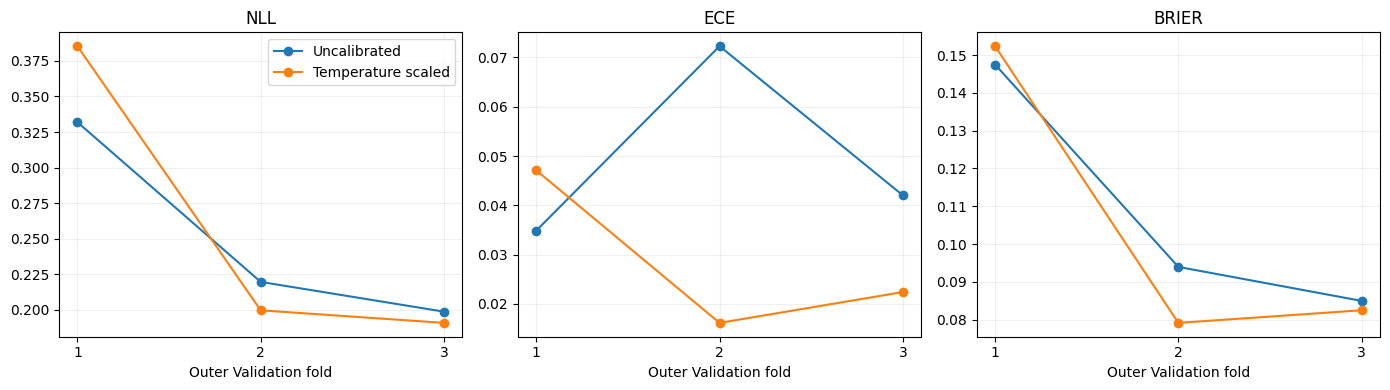

In [10]:
# Summarise paired fold differences; report every fold rather than just means.
comparison=fold_results.pivot(index="fold",columns="method",values=["nll","ece","brier","accuracy"])
display(comparison.round(4))
means=fold_results.groupby("method")[["nll","ece","brier","accuracy"]].mean()
display(means.round(4))
fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,metric in zip(axes,["nll","ece","brier"]):
    for name,frame in fold_results.groupby("method",sort=False):
        ax.plot(frame["fold"],frame[metric],marker="o",label=name)
    ax.set(title=metric.upper(),xlabel="Outer Validation fold",xticks=[1,2,3])
    ax.grid(alpha=0.2)
axes[0].legend()
fig.tight_layout()
plt.show()

**05. Pooled Out-of-Fold reliability diagrams**

Within each model condition, every development base window is held out exactly once. Reliability plots remain descriptive, as overlapping windows and repeated development decisions limit inference.

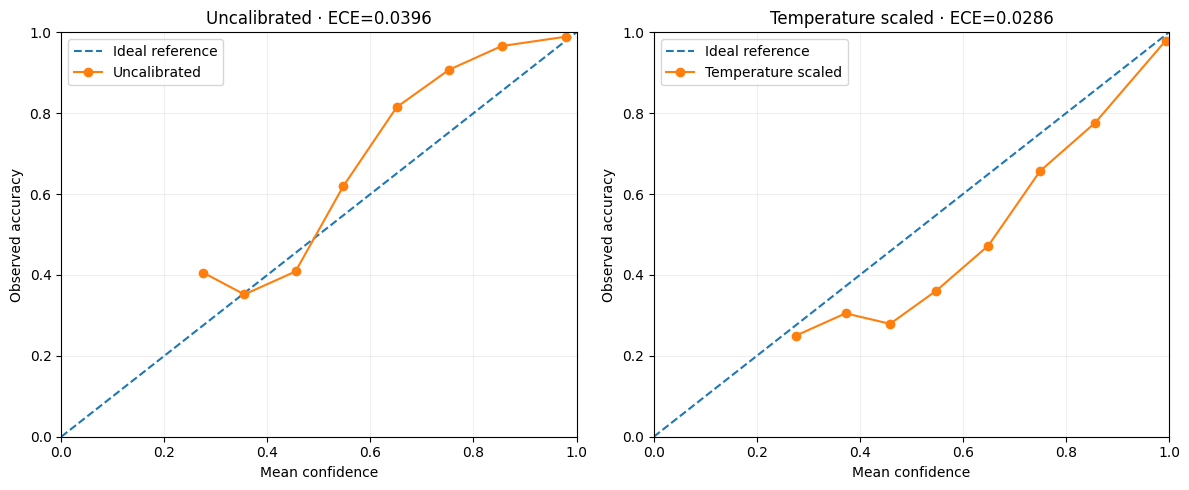

In [11]:
# Check aligned source rows for both methods and plot side-by-side.
fig,axes=plt.subplots(1,2,figsize=(12,5))
for ax,(name,table) in zip(axes,oof.groupby("method",sort=False)):
    table=table.sort_values("source_row")
    probabilities=table[[f"prob_{c}" for c in CLASSES]].to_numpy()
    _,bins,_,metrics=audit_prediction_confidence(
        table["true_label"].to_numpy(),probabilities,
        table["subject_id"].to_numpy(),CLASSES)
    selected=bins[bins["windows"]>0]
    ax.plot([0,1],[0,1],"--",label="Ideal reference")
    ax.plot(selected["mean_confidence"],selected["observed_accuracy"],
            marker="o",label=name)
    ax.set(xlim=(0,1),ylim=(0,1),title=f"{name} · ECE={metrics['ece_10_bins']:.4f}",
           xlabel="Mean confidence",ylabel="Observed accuracy")
    ax.legend()
    ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

**06. Quality gate and interpretation limits**

The original Test IDs never enter these data. Calibration and Validation subjects are separated. Accuracy and top-1 decisions should remain unchanged by positive scalar temperature (allowing ties/numerical edge cases). The estimate is development-only, not deployment-calibrated.

In [12]:
# Assert one held-out score per original base source window and method.
original_rows=set(base.tolist())
for name,part in oof.groupby("method"):
    assert len(part)==len(base)
    assert part["source_row"].is_unique
    assert set(part["source_row"])==original_rows
    assert not(set(part["subject_id"])&RESERVED_TEST)
uncal=oof[oof["method"]=="Uncalibrated"].sort_values("source_row")
cal=oof[oof["method"]=="Temperature scaled"].sort_values("source_row")
raw_p=uncal[[f"prob_{c}" for c in CLASSES]].to_numpy()
new_p=cal[[f"prob_{c}" for c in CLASSES]].to_numpy()
np.testing.assert_array_equal(raw_p.argmax(axis=1),new_p.argmax(axis=1))
assert len(fold_results)==6
assert fold_results["temperature"].gt(0).all()
print("Participant-disjoint calibration and outer Validation: PASSED")
print("Original Test data loaded or scored: NO")
print("Independent final calibration/generalisation: NOT ESTABLISHED")

Participant-disjoint calibration and outer Validation: PASSED
Original Test data loaded or scored: NO
Independent final calibration/generalisation: NOT ESTABLISHED
